In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [133]:
cluster =  pd.read_csv("grova2.csv",header = None)

In [134]:
cluster.columns = ["X","Y","Vx","Vy","Vz"]

In [135]:
cluster

,X,Y,Vx,Vy,Vz
0,15.29,27.30,3.65,1.88,1.93
1,22.51,8.02,3.79,1.39,1.60
2,17.16,15.07,0.14,0.29,3.74
3,58.72,31.59,3.33,1.70,1.69
4,63.48,28.91,1.09,2.80,2.21
...,...,...,...,...,...
10995,37.48,42.22,3.67,3.68,3.66
10996,38.04,33.95,3.24,4.58,4.21
10997,30.26,48.87,4.71,4.71,4.66
10998,41.28,39.03,2.85,4.04,4.45


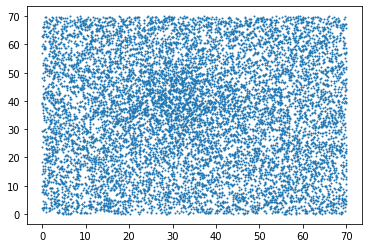

In [136]:
#2D - Coordinates
plt.scatter(cluster["X"],cluster["Y"], s = 1)

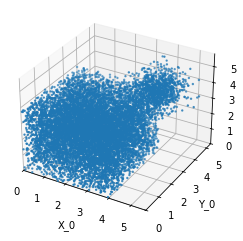

In [137]:
# 3D - How are velocities correlated?
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

X_0, Y_0, Z_0 = [0, 0], [0, 0], [0, 0]
ax.set_xlim([0, max(cluster["Vx"])])
ax.set_ylim([0, max(cluster["Vy"])])
ax.set_zlim([0, max(cluster["Vz"])])
ax.set_xlabel('X_0')
ax.set_ylabel('Y_0')
ax.set_zlabel('Z_0')

ax.scatter(cluster["Vx"],cluster["Vy"],cluster["Vz"], s = 2)

In [138]:
cluster.describe()

,X,Y,Vx,Vy,Vz
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000
mean,34.607379,35.480471,2.175928,2.180388,2.166670
std,19.498853,19.717705,1.246390,1.244227,1.233207
min,0.000000,0.010000,0.000000,0.000000,0.000000
25%,18.380000,19.017500,1.090000,1.100000,1.117500
50%,33.975000,36.040000,2.220000,2.210000,2.180000
75%,51.202500,51.612500,3.270000,3.270000,3.250000
max,69.990000,70.000000,5.650000,5.390000,5.790000


[Text(0.5, 0, 'Vy'), Text(0, 0.5, 'Vz')]

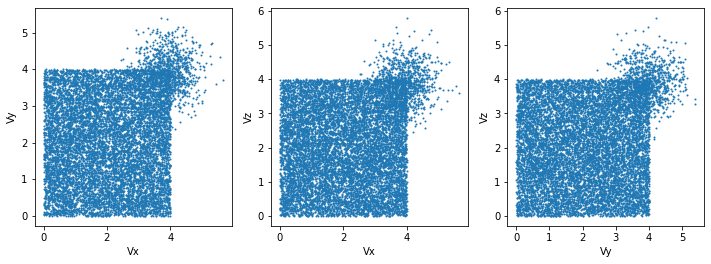

In [139]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster["Vx"],cluster["Vy"], s = 1)
ax1.set(xlabel="Vx", ylabel="Vy")
ax2.scatter(cluster["Vx"],cluster["Vz"], s = 1)
ax2.set(xlabel="Vx", ylabel="Vz")
ax3.scatter(cluster["Vy"],cluster["Vz"], s = 1)
ax3.set(xlabel="Vy", ylabel="Vz")

In [140]:
# სამივე ნახაზში ვხედავ ვარსკვლავებს რომლებიც არიან აუცილებლად გროვის წევრი. 

In [141]:
first_cutoff = 4

# ამოვიღო ინდექსები ამ ვარსკვლავების.
final_cluster = cluster[((cluster["Vx"] >= first_cutoff) & (cluster["Vy"] >= first_cutoff)) | ((cluster["Vx"] >= first_cutoff) & (cluster["Vz"] >= first_cutoff)) | ((cluster["Vy"] >= first_cutoff) & (cluster["Vz"] >= first_cutoff))]

# ჯერჯერობით ამოვარჩიე 396 ვარსკვლავი
final_cluster.shape[0]

396

In [142]:
final_cluster

,X,Y,Vx,Vy,Vz
10000,20.76,39.09,4.02,4.38,3.89
10003,24.05,40.39,4.03,3.79,4.39
10008,28.46,38.55,3.91,4.01,4.04
10009,34.03,39.54,4.21,4.01,4.37
10010,20.99,31.97,3.56,5.00,4.08
...,...,...,...,...,...
10994,15.08,42.59,4.27,4.42,3.67
10996,38.04,33.95,3.24,4.58,4.21
10997,30.26,48.87,4.71,4.71,4.66
10998,41.28,39.03,2.85,4.04,4.45


(0.0, 26.0)

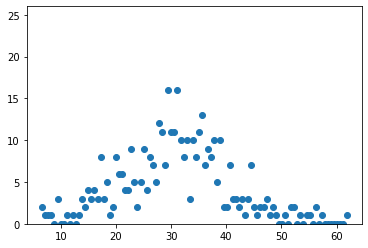

In [143]:
bins = 100

uniform_hist_X = np.histogram(final_cluster["X"], bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 27.0)

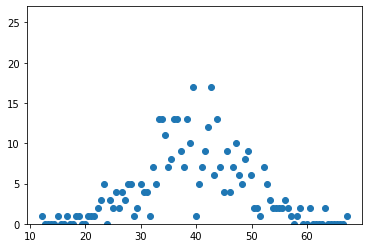

In [144]:
uniform_hist_Y = np.histogram(final_cluster["Y"], bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

In [145]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2/(2*sigma**2))

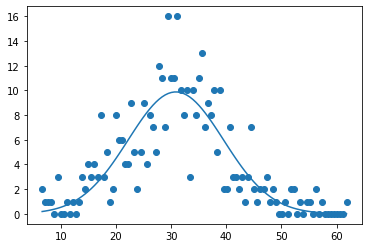

In [146]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), final_cluster["X"].mean(), final_cluster["X"].std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

In [147]:
x_center = popt[1]

In [148]:
residuals = uniform_hist_X[0] - gauss(centers, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_X[0] - uniform_hist_X[0].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

0.7125587159542226

0.6838993412025685

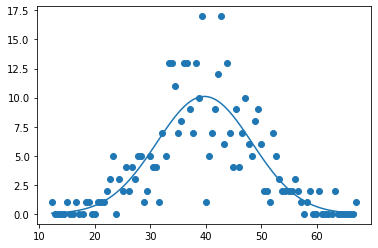

In [149]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_Y[0], p0=[uniform_hist_Y[0].max(), final_cluster["Y"].mean(), final_cluster["Y"].std()])
plt.scatter(centers1, uniform_hist_Y[0])
plt.plot(centers1, gauss(centers1, *popt))
residuals = uniform_hist_Y[0] - gauss(centers1, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_Y[0] - uniform_hist_Y[0].mean())**2)
r2_y = 1 - ss_res / ss_tot
r2_y

In [150]:
y_center = popt[1]

In [151]:
print(x_center, y_center)

30.852371888247326 39.757306521393474


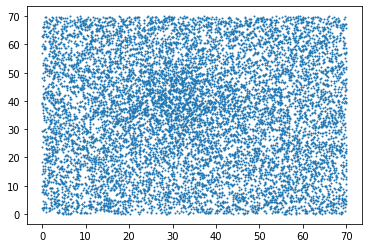

In [152]:
plt.scatter(cluster["X"],cluster["Y"], s = 1)

In [153]:
n = final_cluster.shape[0]

r = 3
n_circ = 50
t = np.linspace(-10*np.pi,10*np.pi,300)

final_radius = r*np.sqrt(50)

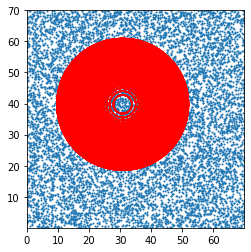

In [154]:
plt.scatter(cluster["X"], cluster["Y"], s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())
plt.gca().set_aspect("equal")

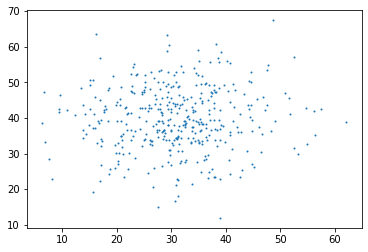

In [155]:
plt.scatter(final_cluster["X"], final_cluster["Y"], s = 1)

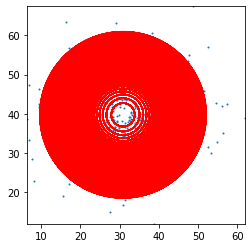

In [156]:
plt.scatter(final_cluster["X"], final_cluster["Y"], s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(final_cluster["X"].min(), final_cluster["X"].max())
plt.ylim(final_cluster["Y"].min(), final_cluster["Y"].max())
plt.gca().set_aspect("equal")

In [157]:
counts = [0] * n_circ
selected = []   # original index labels of stars inside the circles

for i in range(n_circ):
    for j in range(n):
        d2 = (final_cluster["X"].iloc[j] - x_center)**2 + (final_cluster["Y"].iloc[j] - y_center)**2
        if (r*np.sqrt(i))**2 < d2 <= (r*np.sqrt(i+1))**2:
            counts[i] += 1
            selected.append(final_cluster.index[j])

final_coordinates = final_cluster.loc[selected]

In [158]:
sum(counts)

#წრეწირების დახმარებით, ჩამოვედი 365-ზე.

365

In [159]:
n_all = cluster.shape[0]
counts_full = [0] * n_circ

for i in range(n_circ):
    for j in range(n_all):
        if (r*np.sqrt(i))**2<(cluster["X"].iloc[j]-x_center)**2 + (cluster["Y"].iloc[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts_full[i] = counts_full[i] + 1

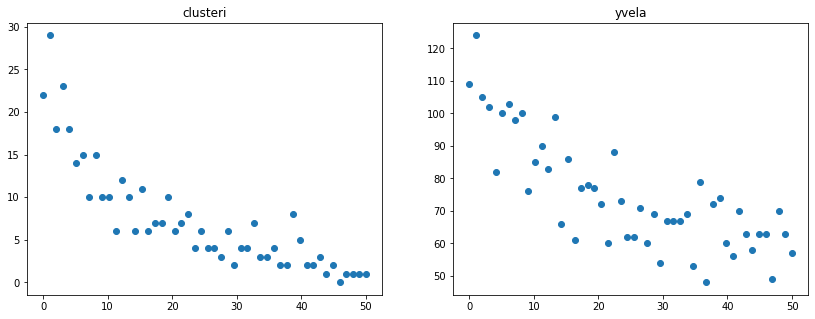

In [160]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize = (14,5))
ax1.scatter(np.linspace(0,n_circ,n_circ),counts)
ax1.set_title("clusteri")
ax2.scatter(np.linspace(0,n_circ,n_circ),counts_full)
ax2.set_title("yvela")

plt.show()

In [161]:
# უნდა გამოვყო ვარსკვლავები, რომლებიც შერეულია.

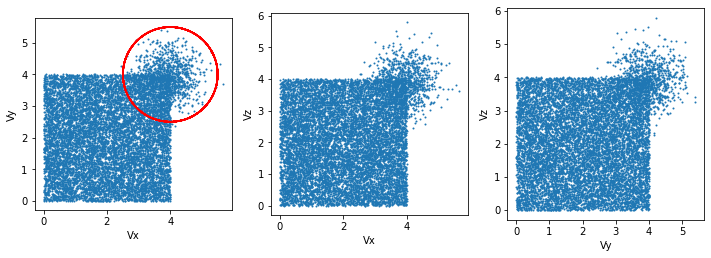

In [162]:
centerr = 4
radiuss = 1.5
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster["Vx"],cluster["Vy"], s = 1)
ax1.set(xlabel="Vx", ylabel="Vy")
ax1.plot(centerr + radiuss*np.cos(t), centerr + radiuss*np.sin(t),c = "r")

ax2.scatter(cluster["Vx"],cluster["Vz"], s = 1)
ax2.set(xlabel="Vx", ylabel="Vz")
ax3.scatter(cluster["Vy"],cluster["Vz"], s = 1)
ax3.set(xlabel="Vy", ylabel="Vz")

for ax in (ax1, ax2, ax3):
    ax.set_aspect("equal")

In [163]:
additional_idx = []   # original index labels of stars inside the velocity circle
for j in range(n_all):
    d2 = (cluster["Vx"].iloc[j] - centerr)**2 + (cluster["Vy"].iloc[j] - centerr)**2
    if d2 <= radiuss**2:
        additional_idx.append(cluster.index[j])

additional_cluster = cluster.loc[additional_idx]

In [164]:
len(additional_cluster)

2136

In [165]:
# remove the stars that are already in final_cluster (compared by their original index)
additional_cluster = additional_cluster[~additional_cluster.index.isin(final_cluster.index)]
len(additional_cluster)

1744

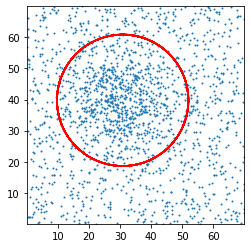

In [166]:
plt.scatter(additional_cluster["X"], additional_cluster["Y"], s = 1)

plt.plot(x_center+final_radius*np.cos(t),y_center+final_radius*np.sin(t),c = "r")
plt.xlim(additional_cluster["X"].min(), additional_cluster["X"].max())
plt.ylim(additional_cluster["Y"].min(), additional_cluster["Y"].max())
plt.gca().set_aspect("equal")

In [167]:
final_additional_idx = []   # original index labels (same numbers as in cluster)
for j in range(len(additional_cluster)):
    d2 = (additional_cluster["X"].iloc[j] - x_center)**2 + (additional_cluster["Y"].iloc[j] - y_center)**2
    if d2 < final_radius**2:
        final_additional_idx.append(additional_cluster.index[j])

final_additional = additional_cluster.loc[final_additional_idx]
final_additional_idx

[38,
 94,
 191,
 247,
 251,
 273,
 276,
 328,
 460,
 468,
 487,
 495,
 613,
 621,
 624,
 699,
 723,
 738,
 753,
 850,
 898,
 952,
 954,
 1021,
 1035,
 1143,
 1183,
 1202,
 1235,
 1244,
 1255,
 1310,
 1378,
 1387,
 1423,
 1432,
 1447,
 1449,
 1450,
 1483,
 1529,
 1559,
 1728,
 1750,
 1781,
 1809,
 1810,
 1826,
 1926,
 1958,
 1984,
 2094,
 2134,
 2158,
 2166,
 2172,
 2209,
 2219,
 2246,
 2272,
 2278,
 2297,
 2314,
 2336,
 2356,
 2363,
 2410,
 2420,
 2441,
 2468,
 2517,
 2523,
 2535,
 2539,
 2566,
 2582,
 2633,
 2685,
 2775,
 2777,
 2791,
 2803,
 2811,
 2816,
 2842,
 2846,
 2849,
 2906,
 3003,
 3013,
 3028,
 3143,
 3146,
 3199,
 3264,
 3265,
 3400,
 3405,
 3457,
 3492,
 3647,
 3650,
 3653,
 3678,
 3686,
 3688,
 3720,
 3781,
 3789,
 3812,
 3857,
 3887,
 3914,
 3960,
 4009,
 4051,
 4061,
 4090,
 4177,
 4184,
 4243,
 4250,
 4260,
 4272,
 4343,
 4346,
 4366,
 4381,
 4416,
 4454,
 4476,
 4497,
 4516,
 4546,
 4582,
 4594,
 4611,
 4628,
 4695,
 4768,
 4807,
 4841,
 4844,
 4853,
 4894,
 4911,
 49

In [168]:
all_cluster_stars = pd.concat([
    final_cluster.assign(group="main"),
    final_additional.assign(group="additional"),
])


In [169]:
all_cluster_stars = all_cluster_stars.sort_index()

In [170]:
all_cluster_stars.head(20)

,X,Y,Vx,Vy,Vz,group
38,34.52,31.33,3.68,3.62,0.74,additional
94,14.77,49.64,3.97,3.12,3.69,additional
191,21.14,55.75,3.58,3.75,2.06,additional
247,14.89,44.35,3.81,2.82,0.92,additional
251,31.66,24.21,2.63,3.65,2.81,additional
273,40.55,29.46,3.96,3.84,3.93,additional
276,27.23,55.79,3.50,3.95,1.48,additional
328,40.91,36.49,3.17,3.02,1.35,additional
460,13.24,46.08,3.21,2.82,3.58,additional
468,22.25,22.52,3.21,2.80,3.66,additional


In [171]:
all_cluster_stars

,X,Y,Vx,Vy,Vz,group
38,34.52,31.33,3.68,3.62,0.74,additional
94,14.77,49.64,3.97,3.12,3.69,additional
191,21.14,55.75,3.58,3.75,2.06,additional
247,14.89,44.35,3.81,2.82,0.92,additional
251,31.66,24.21,2.63,3.65,2.81,additional
...,...,...,...,...,...,...
10995,37.48,42.22,3.67,3.68,3.66,additional
10996,38.04,33.95,3.24,4.58,4.21,main
10997,30.26,48.87,4.71,4.71,4.66,main
10998,41.28,39.03,2.85,4.04,4.45,main


In [193]:
cutoff = 4 - 1
final_cluster = all_cluster_stars[((all_cluster_stars["Vx"] >= cutoff) & (all_cluster_stars["Vy"] >= cutoff)) & (all_cluster_stars["Vz"] >= cutoff)] 
final_cluster

,X,Y,Vx,Vy,Vz,group
94,14.77,49.64,3.97,3.12,3.69,additional
273,40.55,29.46,3.96,3.84,3.93,additional
495,23.54,50.58,3.90,3.96,3.72,additional
738,13.87,45.72,3.44,3.77,3.59,additional
1021,18.29,24.26,3.20,3.95,3.92,additional
...,...,...,...,...,...,...
10994,15.08,42.59,4.27,4.42,3.67,main
10995,37.48,42.22,3.67,3.68,3.66,additional
10996,38.04,33.95,3.24,4.58,4.21,main
10997,30.26,48.87,4.71,4.71,4.66,main


In [194]:
final_cluster.head(50)

,X,Y,Vx,Vy,Vz,group
94,14.77,49.64,3.97,3.12,3.69,additional
273,40.55,29.46,3.96,3.84,3.93,additional
495,23.54,50.58,3.90,3.96,3.72,additional
738,13.87,45.72,3.44,3.77,3.59,additional
1021,18.29,24.26,3.20,3.95,3.92,additional
1255,19.42,47.54,3.76,3.86,3.87,additional
1310,28.98,21.28,3.94,3.35,3.09,additional
1449,32.30,35.27,3.22,3.67,3.62,additional
1559,20.13,23.05,3.03,3.81,3.60,additional
2158,26.40,47.45,3.74,3.96,3.84,additional


In [195]:
idx

Int64Index([   38,    94,   191,   247,   251,   273,   276,   328,   460,
              468,
            ...
            10989, 10990, 10991, 10993, 10994, 10995, 10996, 10997, 10998,
            10999],
           dtype='int64', length=1266)

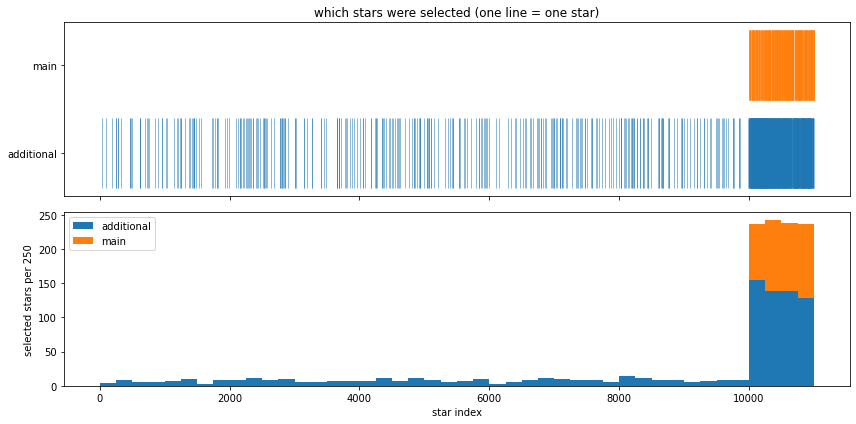

In [196]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
groups = sorted(all_cluster_stars["group"].unique())

# 1) barcode: one vertical line per selected star
for row, (name, grp) in enumerate(all_cluster_stars.groupby("group")):
    ax1.vlines(grp.index, row, row + 0.8, lw=0.5, color=f"C{row}")
ax1.set_yticks([0.4, 1.4])
ax1.set_yticklabels(groups)
ax1.set_title("which stars were selected (one line = one star)")

# 2) histogram: how many selected stars in each block of 250 indexes
bins = np.arange(0, len(cluster) + 250, 250)
ax2.hist([grp.index for _, grp in all_cluster_stars.groupby("group")],
         bins=bins, stacked=True, label=groups)
ax2.set(xlabel="star index", ylabel="selected stars per 250")
ax2.legend()

plt.tight_layout()
plt.show()


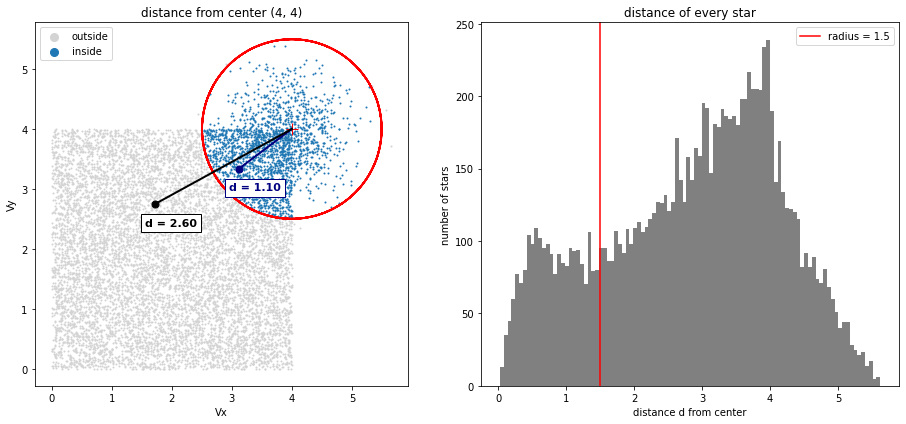

In [ ]:
d2 = (cluster["Vx"] - centerr)**2 + (cluster["Vy"] - centerr)**2
d = np.sqrt(d2)
inside = d2 <= radiuss**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# left: the stars, the circle, and the distance of two example stars
ax1.scatter(cluster["Vx"][~inside], cluster["Vy"][~inside], s=1, c="lightgray", label="outside")
ax1.scatter(cluster["Vx"][inside], cluster["Vy"][inside], s=1, c="tab:blue", label="inside")
ax1.plot(centerr + radiuss*np.cos(t), centerr + radiuss*np.sin(t), c="r")
ax1.plot(centerr, centerr, "r+", ms=12)

example_in = (d - 1.1).abs()[(cluster["Vx"] < 3.2) & (cluster["Vy"] < 3.6)].idxmin()
example_out = (d - 2.6).abs()[(cluster["Vx"] < 2.5) & (cluster["Vy"] > 2.5)].idxmin()

for j, col in [(example_in, "navy"), (example_out, "black")]:
    vx, vy = cluster.loc[j, "Vx"], cluster.loc[j, "Vy"]
    ax1.plot([centerr, vx], [centerr, vy], c=col, lw=2)   # the distance line
    ax1.plot(vx, vy, "o", c=col, ms=7)
    ax1.annotate(f"d = {d[j]:.2f}", (vx, vy), xytext=(-10, -22), textcoords="offset points",
                 color=col, fontsize=11, weight="bold", bbox=dict(fc="white", ec=col))

ax1.set(xlabel="Vx", ylabel="Vy", title=f"distance from center ({centerr}, {centerr})")
ax1.set_aspect("equal")
ax1.legend(markerscale=8, loc="upper left")

# right: distance of every star
ax2.hist(d, bins=100, color="gray")
ax2.axvline(radiuss, c="r", label=f"radius = {radiuss}")
ax2.set(xlabel="distance d from center", ylabel="number of stars", title="distance of every star")
ax2.legend()

plt.tight_layout()
plt.show()
